<a href="https://colab.research.google.com/github/Don4141/ProductPriceAI/blob/main/Training_OpenSource_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mount google drive

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import os
os.chdir("/content")
#Clone repo after a new Colab runtime as the previous will be erased
!git clone https://github.com/Don4141/ProductPriceAI.git

#Set repository as working directory
os.chdir("/content/ProductPriceAI")

#Verify
print("Repo exist", os.path.exists("/content/ProductPriceAI"))
print("Current working directory", os.getcwd())

Cloning into 'ProductPriceAI'...
remote: Enumerating objects: 204, done.
remote: Counting objects: 100% (204/204), done.
remote: Compressing objects: 100% (165/165), done.
remote: Total 204 (delta 106), reused 92 (delta 30), pack-reused 0 (from 0)
Receiving objects: 100% (204/204), 17.32 MiB | 16.83 MiB/s, done.
Resolving deltas: 100% (106/106), done.
Repo exist True
Current working directory /content/ProductPriceAI


In [ ]:
!pip install -q --upgrade bitsandbytes==0.48.2 trl==0.25.1 transformers==4.57.6
#!pip install -U trl
#!pip install -U bitsandbytes>=0.46.1

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
%pip uninstall -y gradio gradio-client diffusers

Found existing installation: gradio 6.31.0
Uninstalling gradio-6.31.0:
  Successfully uninstalled gradio-6.31.0
Found existing installation: gradio_client 2.7.2
Uninstalling gradio_client-2.7.2:
  Successfully uninstalled gradio_client-2.7.2
Found existing installation: diffusers 0.42.1
Uninstalling diffusers-0.42.1:
  Successfully uninstalled diffusers-0.42.1


In [ ]:
#imports
import os
import re
import math
import numpy as np
import torch
import wandb
import transformers
import trl
import peft
import bitsandbytes
import huggingface_hub
from tqdm import tqdm
from pricer.items import Item
from tqdm.notebook import tqdm
from transformers import AutoTokenizer
from google.colab import userdata
from huggingface_hub import login
import transformers
from peft import LoraConfig, PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer, TrainingArguments, set_seed, BitsAndBytesConfig
from trl import SFTTrainer, SFTConfig
from datasets import load_dataset, Dataset, DatasetDict
from datetime import datetime
import matplotlib.pyplot as plt

print("All LLM training libraries imported successfully!")

All LLM training libraries imported successfully!


In [ ]:
# Load API credentials
for key in ["OPENAI_API_KEY", "ANTHROPIC_API_KEY", "GROQ_API_KEY", "GITHUB_TOKEN", "HF_TOKEN"]:
  os.environ[key] = userdata.get(key)

In [ ]:
 #Verify if API keys are loaded
for key in ["OPENAI_API_KEY", "ANTHROPIC_API_KEY", "GROQ_API_KEY", "GITHUB_TOKEN", "HF_TOKEN"]:
    print(f"{key}: {'loaded' if os.getenv(key) else 'Missing'}")

OPENAI_API_KEY: loaded
ANTHROPIC_API_KEY: loaded
GROQ_API_KEY: loaded
GITHUB_TOKEN: loaded
HF_TOKEN: loaded


Verify Colab can retrieve your GitHub secret.

Load the preprocessed dataset containing 819,998 products from Hugging Face

In [ ]:
#Define configuration constants for fine-tuning Llama-3.2-3B
BASE_MODEL = "meta-llama/Llama-3.2-3B"
PROJECT_NAME = "price"
#Generate a timestamp-based run identifier
RUN_NAME = f"{datetime.now():%Y-%m-%d_%H.%M.%S}"
#Combine project name and timestamp to identify the run
PROJECT_RUN_NAME = f"{PROJECT_NAME}-{RUN_NAME}"

#Use the lite dataset for testing the fine-tuning workflow
LITE_MODE = True
DATA_USER = "sadjei65320"
#Select the Lite dataset
DATASET_NAME = f"{DATA_USER}/items_prompts_lite" if LITE_MODE else f"{DATA_USER}/items_prompts_full"
#Hugging Face repository ID for the final fine-tuned model
#FINETUNED_MODEL = f"{DATA_USER}/price-2025-11-30_15.10.55-lite"

In [ ]:
# Load the Base Model using 8 bit
quant_config = BitsAndBytesConfig(load_in_8bit=True)
#Load the pretrained Llama-3.2-3B
base_model = AutoModelForCausalLM.from_pretrained(BASE_MODEL, quantization_config=quant_config, device_map="auto")

config.json:   0%|          | 0.00/844 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/4.97G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/1.46G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]

In [ ]:
# Load the Base Model without quantization
base_model = AutoModelForCausalLM.from_pretrained(BASE_MODEL, device_map="auto")
print(f"Memory footprint: {base_model.get_memory_footprint() / 1e9:,.1f} GB")

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Memory footprint: 12.9 GB


In [ ]:
#Architecture of Llama-3.2-3B model before quantization
base_model

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(128256, 3072)
    (layers): ModuleList(
      (0-27): 28 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=3072, out_features=3072, bias=False)
          (k_proj): Linear(in_features=3072, out_features=1024, bias=False)
          (v_proj): Linear(in_features=3072, out_features=1024, bias=False)
          (o_proj): Linear(in_features=3072, out_features=3072, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=3072, out_features=8192, bias=False)
          (up_proj): Linear(in_features=3072, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=3072, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): LlamaRMSNorm((3072,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((3072,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((3072,), eps=1e-05)
    (

In [ ]:
#Configure the pretrained model for 4 bit quantization
quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_quant_type="nf4")

#Load the Base Model using 4 bit model-weight quantization
base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL, quantization_config=quant_config, device_map="auto")

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:212: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


In [ ]:
print(f"Memory footprint: {base_model.get_memory_footprint() / 1e9:,.2f} GB")

Memory footprint: 2.20 GB


In [ ]:
#Architecture of Llama-3.2-3B model after applying 4-bit quantization
base_model

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(128256, 3072)
    (layers): ModuleList(
      (0-27): 28 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear4bit(in_features=3072, out_features=3072, bias=False)
          (k_proj): Linear4bit(in_features=3072, out_features=1024, bias=False)
          (v_proj): Linear4bit(in_features=3072, out_features=1024, bias=False)
          (o_proj): Linear4bit(in_features=3072, out_features=3072, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear4bit(in_features=3072, out_features=8192, bias=False)
          (up_proj): Linear4bit(in_features=3072, out_features=8192, bias=False)
          (down_proj): Linear4bit(in_features=8192, out_features=3072, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): LlamaRMSNorm((3072,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((3072,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNo

#### LoRA Parameter Estimation for Llama 3.2-3B Fine-Tuning

Before fine-tuning **Llama 3.2-3B** on the preprocessed full dataset, let's estimate the number of trainable parameters introduced by **Low-Rank Adaptation (LoRA)** using a rank of 256 (`r=256`).

Seven linear projection modules within the attention and feed-forward/MLP blocks are selected as LoRA targets: attention (`q_proj`, `k_proj`, `v_proj`, `o_proj`) and MLP (`gate_proj`, `up_proj`, `down_proj`). Each targeted module introduces two trainable low-rank matrices (A and B), enabling parameter-efficient fine-tuning while keeping the pretrained model weights frozen.

The calculation below determines the **total number of trainable LoRA parameters across all 28 transformer layers** and estimates their memory footprint assuming FP32 precision (4 bytes per parameter). This provides an initial assessment of the memory required to store the LoRA adapter weights before fine-tuning.

In [ ]:

#Define the LoRA rank, which determines the dimensions of the adapter matrices
r = 256
#Calculate LoRA parameters for attention layers. Each layer has two trainable matrices: lora_A and lora_B
#Query layer: input dimension = 3072, output dimension = 3072
lora_q_proj = 3072 * r + 3072 * r
#Key layer: input dimension = 3072, output dimension = 1024
lora_k_proj = 3072 * r + 1024 * r
#Value layer: input dimension = 3072, output dimension = 1024
lora_v_proj = 3072 * r + 1024 * r
#Output layer: input dimension = 3072, output dimension = 3072
lora_o_proj = 3072 * r + 3072 * r

#Calculate LoRA parameters for MLP (feed-forward) layers
#Gate layer: input dimension = 3072, output dimension = 8192
lora_gate_proj = 3072 * r + 8192 * r
#Up layer: input dimension = 3072, output dimension = 8192
lora_up_proj = 3072 * r + 8192 * r
#Down layer: input dimension = 8192, output dimension = 3072
lora_down_proj = 3072 * r + 8192 * r

#Sum the LoRA parameters across all seven layers in one transformer layer
lora_layer = lora_q_proj + lora_k_proj + lora_v_proj + lora_o_proj + lora_gate_proj + lora_up_proj + lora_down_proj

#Calculate total trainable LoRA parameters across all 28 transformer layers
params = lora_layer * 28

#Estimate memory usage in MB, assuming FP32 precision (4 bytes per parameter)
size = (params * 4) / 1_000_000

#Display the total number of LoRA parameters and their estimated memory footprint
print(f"Total number of params: {params:,} and size {size:,.1f}MB")

Total number of params: 389,021,696 and size 1,556.1MB


Load the preprocessed dataset containing 819,998 products from Hugging Face

In [ ]:
dataset =f"{DATA_USER}/items_full"
train, val, test = Item.from_hub(dataset)
items = train + val + test

print(f"Loaded {len(train):,} training items, {len(val):,} validation items, {len(test):,} test items")

README.md:   0%|          | 0.00/744 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/237M [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/3.00M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/3.00M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/799998 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Loaded 799,998 training items, 10,000 validation items, 10,000 test items


In [ ]:
#Assign the pretrained Llama 3.2-3B model to a variable
BASE_MODEL = "meta-llama/Llama-3.2-3B"
#Load the model's pretrained tokenizer to convert text into token IDs
#compatible with the model's vocabulary and tokenization scheme
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/301 [00:00<?, ?B/s]

Apply the pretrained tokenizer to each product summary in the dataset to determine its token length. The resulting list will contain the total number of tokens in each summary, excluding special tokens such as beginning-of-sequence (BOS) and end-of-sequence (EOS) tokens.

In [ ]:
#Count the number of tokens in each product summary using the Llama 3.2-3B tokenizer.
token_counts = [item.count_tokens(tokenizer) for item in tqdm(items)]

  0%|          | 0/819998 [00:00<?, ?it/s]

Assess the distribution of token lengths across the dataset before fine-tuning.

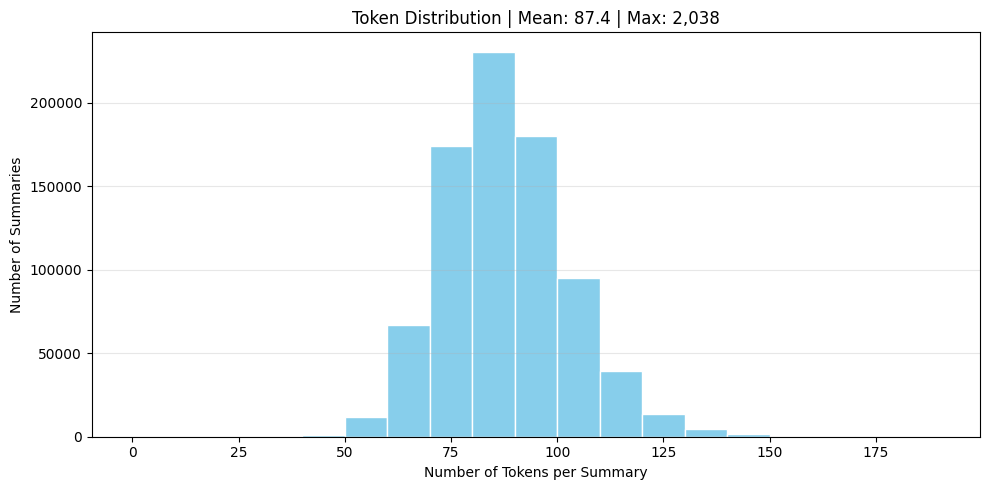

In [ ]:
#Calculate token statistics
mean_tokens = np.mean(token_counts)
max_tokens = np.max(token_counts)

#Plot the distribution of token lengths
plt.figure(figsize=(10, 5))
plt.hist(token_counts, bins=range(0, 200, 10),
         color="skyblue", edgecolor="white")

plt.title(f"Token Distribution | Mean: {mean_tokens:,.1f} | Max: {max_tokens:,}")
plt.xlabel("Number of Tokens per Summary")
plt.ylabel("Number of Summaries")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

##### The histogram illustrates the token length distributions across the 819,998 product summaries in the dataset, tokenized using the Llama 3.2-3B tokenizer.

##### Most of the product summaries contain approximately 70 to 100 tokens, with an average of about 87.4 tokens and a maximum of 2,038 tokens. Small proportion of summaries appear substantially longer than average.

----

Let's experiment with a token length cutoff to truncate unusually long product summaries. Given the large size of the training dataset, limiting the maximum number of tokens processed per summary can help reduce GPU memory requirements, computational cost, and training time during fine-tuning.

We'll begin with a 110 token cutoff as an initial threshold. Product summaries exceeding this limit will require truncation, potentially resulting in the loss of information relevant to price prediction. Therefore, we'll first evaluate the number and percentage of affected summaries before applying the cutoff during model training.

In [ ]:
#Define the maximum token length for product summaries
CUTOFF = 110
#Count summaries exceeding the cutoff
cut = len([count for count in token_counts if count > CUTOFF])
#Display the number and percentage of summaries requiring truncation
print(f"With this CUTOFF, we will truncate {cut:,} items which is {cut/len(items):.1%}")

With this CUTOFF, we will truncate 53,922 items which is 6.6%


Only 6.6% of product summaries exceed the 110 token cutoff, indicating that the selected threshold is reasonable for balancing computational efficiency and information retention. Since 93.4% of summaries fall within this limit, most summaries will remain intact during fine-tuning. The relatively small proportion of product summaries requiring truncation suggests that this preprocessing step is likely to have a limited overall impact on price prediction performance. This assumption was evaluated through the model evaluation.

In [ ]:
#Display a product summary before truncation
print(train[0].summary)

Title: Business Source Transparent Glossy Tape – Pack of 72  
Category: Office Supplies  
Brand: Business Source  
Description: A translucent, glossy tape ideal for mending, splicing, and holding items.  
Details: Each 3/4" x 1000" roll features a 1" core, is photo‑safe, accepts ink/pencil/marker, and is practically invisible on most surfaces.


#### Preparing Prompts and Completions for Supervised Fine-Tuning



Prepare the product summaries and their corresponding prices for supervised fine-tuning of Llama 3.2-3B. First, tokenize each product summary using the pretrained Llama 3.2-3B tokenizer and truncate summaries exceeding the 110 token cutoff.

Combined each processed summary with a predefined question, **"What does this cost to the nearest dollar?"**, and a response prefix, **"Price is $"**, to construct a structured input prompt for the model.

Finally, each product's actual price is formatted as the target completion, with optional rounding to the nearest dollar. This process is implemented using the `make_prompts()` method defined in the `item.py` module.

The resulting prompt-completion pairs will enable the model to learn the relationship between product descriptions and their corresponding prices during fine-tuning.

In [ ]:
#Generate prompts and completions for the training and validation sets
#Apply the 110-token summary cutoff and round target prices to the nearest dollar
for item in tqdm(train+val):
    item.make_prompts(tokenizer, CUTOFF, True)

#Generate prompts and completions for the test set
#Apply the same token cutoff but preserve the original target prices
for item in tqdm(test):
    item.make_prompts(tokenizer, CUTOFF, False)

  0%|          | 0/809998 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

In [ ]:
#Display a product summary from the test set after processing
print("PROMPT:")
print(test[0].prompt)
print("COMPLETION:")
print(test[0].completion)

PROMPT:
What does this cost to the nearest dollar?

Title: Batman 6" Ultimate Figure Pack  
Category: Toys  
Brand: Mattel  
Description: A 6‑inch poseable Batman figure set that transforms Bruce Wayne’s office into a retro Batcave with classic accessories.  
Details: Includes a Bruce Wayne head, Batman figure, swiveling bookcase, hidden weapons, and iconic gadgets.

Price is $
COMPLETION:
58.73


In [ ]:
#Count the tokens in each generated prompt across the dataset
prompt_token_counts = [item.count_prompt_tokens(tokenizer) for item in tqdm(items)]

  0%|          | 0/819998 [00:00<?, ?it/s]

#### Assess the distribution of the prompt token lengths after preprocessing for supervised fine-tuning

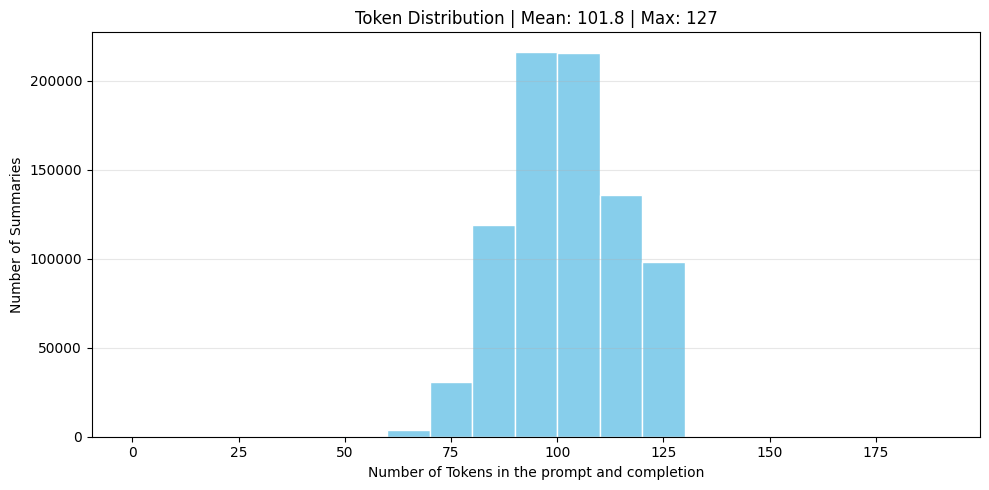

In [ ]:
#Calculate token statistics
mean_tokens = np.mean(prompt_token_counts)
max_tokens = np.max(prompt_token_counts)

#Plot the distribution of token lengths
plt.figure(figsize=(10, 5))
plt.hist(prompt_token_counts, bins=range(0, 200, 10),
         color="skyblue", edgecolor="white")

plt.title(f"Token Distribution | Mean: {mean_tokens:,.1f} | Max: {max_tokens:,}")
plt.xlabel("Number of Tokens in the prompt and completion")
plt.ylabel("Number of Summaries")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
#Push the processed dataset to Hugging Face
username = "sadjei65320"
dataset = f"{username}/items_prompts_full"

Item.push_prompts_to_hub(dataset, train, val, test)

Setting num_proc from 1 back to 1 for the train split to disable multiprocessing as it only contains one shard.


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/4 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /tmp/tmp_7tcheh_.parquet    :   0%|          |  524kB /  171MB            

... (11 outputs left out)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /tmp/tmp01ge3ghw.parquet    :  24%|##4       |  525kB / 2.17MB            

Validating                    :           |   0%            

In [ ]:
#Constants
BASE_MODEL = "meta-llama/Llama-3.2-3B"
PROJECT_NAME = "price"
HF_USER = "sadjei65320"
DATA_USER = "sadjei65320"
DATASET_NAME = f"{DATA_USER}/items_prompts_full"

RUN_NAME =  f"{datetime.now():%Y-%m-%d_%H.%M.%S}"
PROJECT_RUN_NAME = f"{PROJECT_NAME}-{RUN_NAME}"
HUB_MODEL_NAME = f"{HF_USER}/{PROJECT_RUN_NAME}"

#Hyper-parameters - overall
EPOCHS = 3
BATCH_SIZE = 128
MAX_SEQUENCE_LENGTH = 128
GRADIENT_ACCUMULATION_STEPS = 1

#Hyper-parameters - QLoRA
QUANT_4_BIT = True
LORA_R = 256
LORA_ALPHA = LORA_R * 2
ATTENTION_LAYERS = ["q_proj", "v_proj", "k_proj", "o_proj"]
MLP_LAYERS = ["gate_proj", "up_proj", "down_proj"]
TARGET_MODULES = ATTENTION_LAYERS + MLP_LAYERS
LORA_DROPOUT = 0.1

#Hyper-parameters - training
LEARNING_RATE = 1e-4
WARMUP_RATIO = 0.01
LR_SCHEDULER_TYPE = 'cosine'
WEIGHT_DECAY = 0.001
OPTIMIZER = "paged_adamw_32bit"
capability = torch.cuda.get_device_capability()
use_bf16 = capability[0] >= 8

#Tracking
VAL_SIZE = 1000
LOG_STEPS = 10
SAVE_STEPS = 200
LOG_TO_WANDB = True

In [ ]:
#Log in to Weights & Biases
wandb_api_key = userdata.get('WANDB_API_KEY')
os.environ["WANDB_API_KEY"] = wandb_api_key
wandb.login()

#Configure Weights & Biases to record against our project
os.environ["WANDB_PROJECT"] = PROJECT_NAME
os.environ["WANDB_LOG_MODEL"] = "false"
os.environ["WANDB_WATCH"] = "false"

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: sadjei65320 (sadjei65320-personal-studies) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [ ]:
dataset = load_dataset(DATASET_NAME)
train = dataset['train']
val = dataset['val'].select(range(VAL_SIZE))
test = dataset['test']

README.md:   0%|          | 0.00/520 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/171M [00:00<?, ?B/s]

data/val-00000-of-00001.parquet:   0%|          | 0.00/2.15M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/2.17M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/799998 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

In [ ]:
if LOG_TO_WANDB:
  wandb.init(project=PROJECT_NAME, name=RUN_NAME)

In [ ]:
#Pick the right quantization
if QUANT_4_BIT:
  quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.bfloat16 if use_bf16 else torch.float16,
    bnb_4bit_quant_type="nf4"
  )
else:
  quant_config = BitsAndBytesConfig(
    load_in_8bit=True,
    bnb_8bit_compute_dtype=torch.bfloat16 if use_bf16 else torch.float16,
  )

In [ ]:
#Load the Tokenizer and the Model
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, trust_remote_code=True)
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    quantization_config=quant_config,
    device_map="auto",
)
base_model.generation_config.pad_token_id = tokenizer.pad_token_id

print(f"Memory footprint: {base_model.get_memory_footprint() / 1e6:.1f} MB")

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/301 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/844 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

... (2 outputs left out)

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:212: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


generation_config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]

Memory footprint: 2197.6 MB


In [ ]:
# LoRA Parameters
lora_parameters = LoraConfig(
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,
    r=LORA_R,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=TARGET_MODULES,
)

In [ ]:
#Training parameters
train_parameters = SFTConfig(
    output_dir=PROJECT_RUN_NAME,

    #Training
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,

    #Memory optimization
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},

    #Optimizer
    optim=OPTIMIZER,
    learning_rate=LEARNING_RATE,
    weight_decay=0.001,
    max_grad_norm=0.3,

    #Precision
    fp16=not use_bf16,
    bf16=use_bf16,

    #Learning rate schedule
    warmup_ratio=WARMUP_RATIO,
    lr_scheduler_type=LR_SCHEDULER_TYPE,

    #Sequence configuration
    max_length=MAX_SEQUENCE_LENGTH,
    group_by_length=True,
    max_steps=-1,

    #Logging
    logging_steps=LOG_STEPS,
    report_to="wandb" if LOG_TO_WANDB else None,
    run_name=RUN_NAME,

    #Checkpoints
    save_strategy="steps",
    save_steps=SAVE_STEPS,
    save_total_limit=10,

    #Hugging Face Hub
    hub_strategy="every_save",
    push_to_hub=True,
    hub_model_id=HUB_MODEL_NAME,
    hub_private_repo=True,

    #Evaluation
    eval_strategy="steps",
    eval_steps=SAVE_STEPS)

#### Create trainer

In [ ]:
fine_tuning = SFTTrainer(
    model=base_model,
    train_dataset=train,
    eval_dataset=val,
    peft_config=lora_parameters,
    args=train_parameters
)

Adding EOS to train dataset:   0%|          | 0/799998 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/799998 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/799998 [00:00<?, ? examples/s]

Adding EOS to eval dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

In [ ]:
# Fine-tune!
fine_tuning.train()
# Push our fine-tuned model to Hugging Face
fine_tuning.model.push_to_hub(PROJECT_RUN_NAME, private=True)
print(f"Saved to the hub: {PROJECT_RUN_NAME}")

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': None}.


Step,Training Loss,Validation Loss,Entropy,Num Tokens,Mean Token Accuracy
200,1.304500,1.294526,3.057368,2660536.000000,0.757500


Step,Training Loss,Validation Loss,Entropy,Num Tokens,Mean Token Accuracy
200,1.304500,1.294526,3.057368,2660536.000000,0.757500
400,1.257100,1.282584,3.546551,5318808.000000,0.758750


In [ ]:
if LOG_TO_WANDB:
  wandb.finish()

# More on Optimizers

https://huggingface.co/docs/transformers/main/en/perf_train_gpu_one#optimizers

The most common is Adam or AdamW (Adam with Weight Decay).  
Adam achieves good convergence by storing the rolling average of the previous gradients; however, it adds an additional memory footprint of the order of the number of model parameters.

## Now load the Tokenizer and Model

The model is "quantized" - we are reducing the precision to 4 bits.

# AND NOW

## We set up the configuration for Training

We need to create 2 objects:

A LoraConfig object with our hyperparameters for LoRA

An SFTConfig with our overall Training parameters

## In the next cell, we kick off fine-tuning!

This will run for some time, uploading to the hub every SAVE_STEPS steps.

After some time, Google might stop your colab. For people on free plans, it can happen whenever Google is low on resources. For anyone on paid plans, they can give you up to 24 hours, but there's no guarantee.

If your server is stopped, you can follow my colab here to resume from your last save:

https://colab.research.google.com/drive/1qGTDVIas_Vwoby4UVi2vwsU0tHXy8OMO#scrollTo=R_O04fKxMMT-

I've saved this colab with my final run in the output so you can see the example. The trick is that I needed to set `is_trainable=True` when loading the fine_tuned model.

### Anyway, with that in mind, let's kick this off!

In [ ]:
import stat
#Authenticate Colab to git push changes to my repository
token = userdata.get("GITHUB_TOKEN")

askpass_path = "/tmp/github_askpass.sh" #temporarily provide secret to Git through ASKPASS helper rather than embedding it in the remote URL

with open(askpass_path, "w") as f:
    f.write("""#!/bin/sh
case "$1" in
  *Username*) echo "$GITHUB_USERNAME" ;;
  *Password*) echo "$GITHUB_TOKEN" ;;
esac
""")

os.chmod(askpass_path, stat.S_IRUSR | stat.S_IWUSR | stat.S_IXUSR)
os.environ["GITHUB_USERNAME"] = "Don4141"
os.environ["GITHUB_TOKEN"] = token
os.environ["GIT_ASKPASS"] = askpass_path
os.environ["GIT_TERMINAL_PROMPT"] = "0"

print("GitHub authentication configured for this runtime.")

GitHub authentication configured for this runtime.
